<a href="https://colab.research.google.com/github/kolavalisanjana30/2520030614_ML/blob/main/Project/EDA_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("/content/diabetes_data_upload.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (520, 17)


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
for column in df.columns:
    print("-", column)

Number of Rows: 520
Number of Columns: 17

Column Names:
- Age
- Gender
- Polyuria
- Polydipsia
- sudden weight loss
- weakness
- Polyphagia
- Genital thrush
- visual blurring
- Itching
- Irritability
- delayed healing
- partial paresis
- muscle stiffness
- Alopecia
- Obesity
- class


In [4]:
print(df.dtypes)

Age                    int64
Gender                object
Polyuria              object
Polydipsia            object
sudden weight loss    object
weakness              object
Polyphagia            object
Genital thrush        object
visual blurring       object
Itching               object
Irritability          object
delayed healing       object
partial paresis       object
muscle stiffness      object
Alopecia              object
Obesity               object
class                 object
dtype: object


In [5]:
missing_values = df.isnull().sum()

print("Missing Values:")
display(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:


,0
Age,0
Gender,0
Polyuria,0
Polydipsia,0
sudden weight loss,0
weakness,0
Polyphagia,0
Genital thrush,0
visual blurring,0
Itching,0



Total Missing Values: 0


In [6]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 269


class
Positive    320
Negative    200
Name: count, dtype: int64


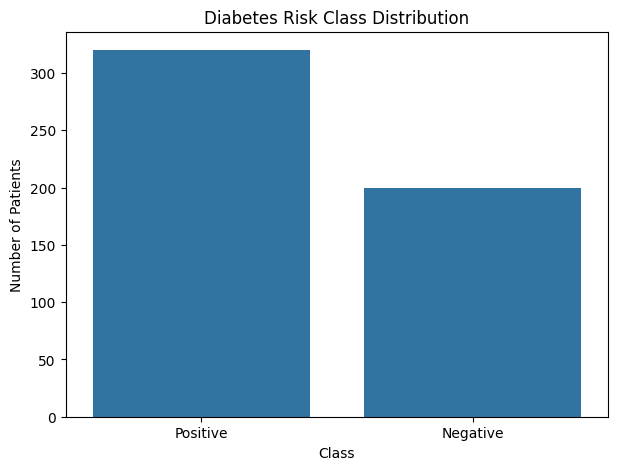

In [7]:
class_counts = df["class"].value_counts()

print(class_counts)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Diabetes Risk Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Patients")

plt.show()

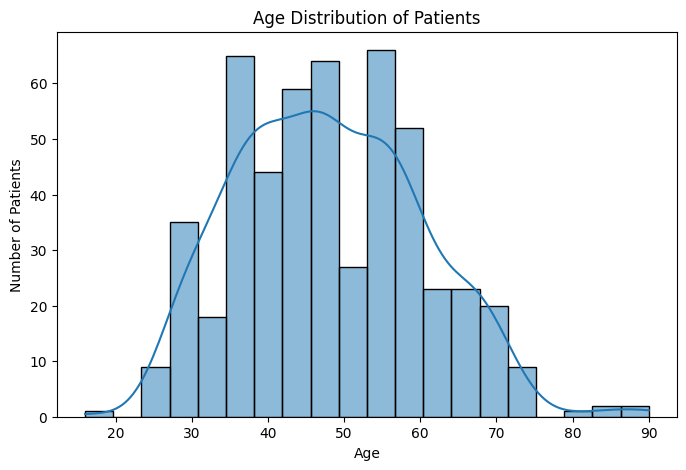

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

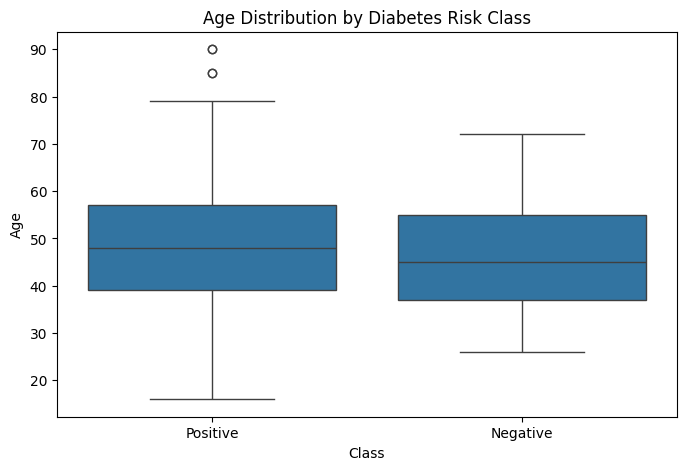

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="class",
    y="Age"
)

plt.title("Age Distribution by Diabetes Risk Class")
plt.xlabel("Class")
plt.ylabel("Age")

plt.show()

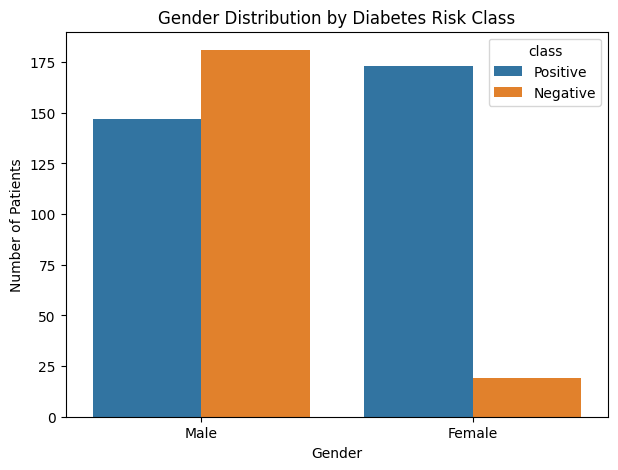

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Gender",
    hue="class"
)

plt.title("Gender Distribution by Diabetes Risk Class")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")

plt.show()

In [11]:
symptoms = [
    "Polyuria",
    "Polydipsia",
    "sudden weight loss",
    "weakness",
    "Polyphagia",
    "Genital thrush",
    "visual blurring",
    "Itching",
    "Irritability",
    "delayed healing",
    "partial paresis",
    "muscle stiffness",
    "Alopecia",
    "Obesity"
]

print("Number of symptoms analyzed:", len(symptoms))

Number of symptoms analyzed: 14


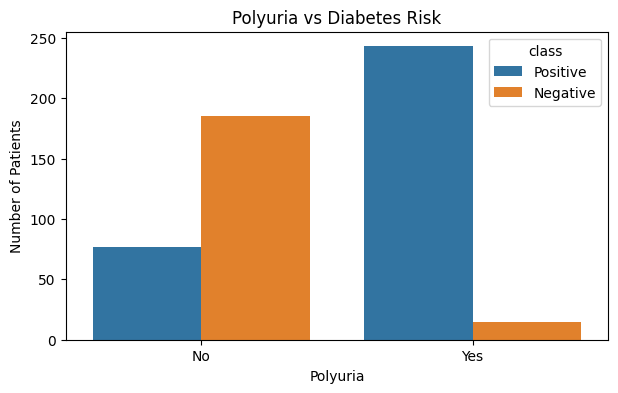

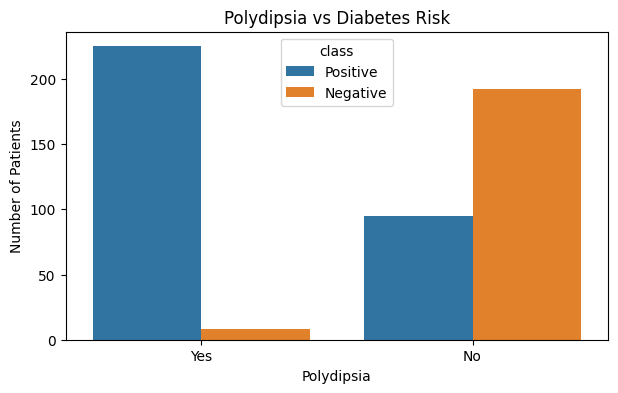

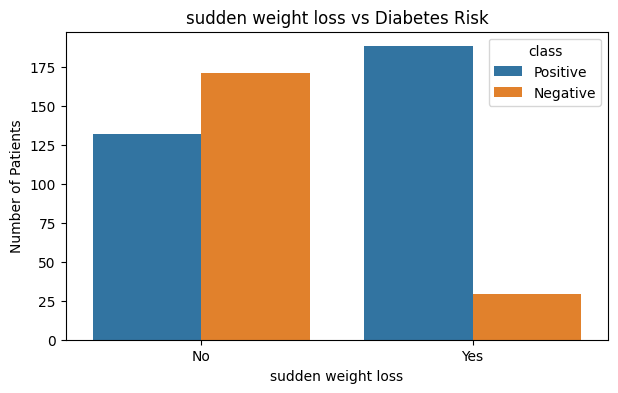

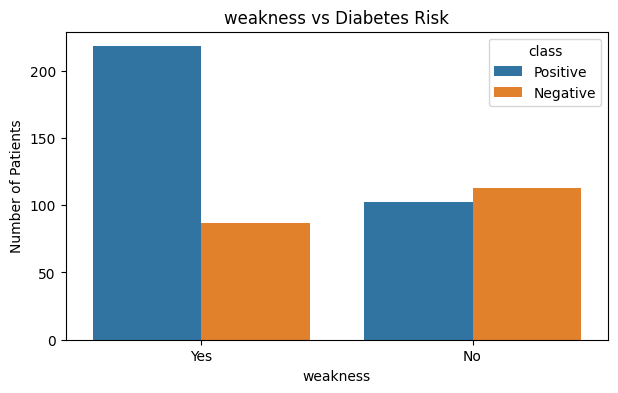

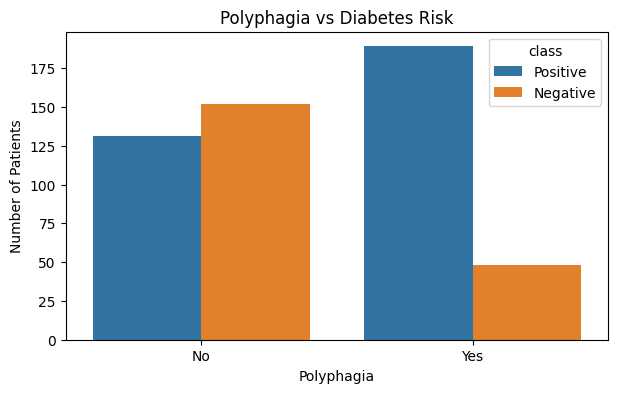

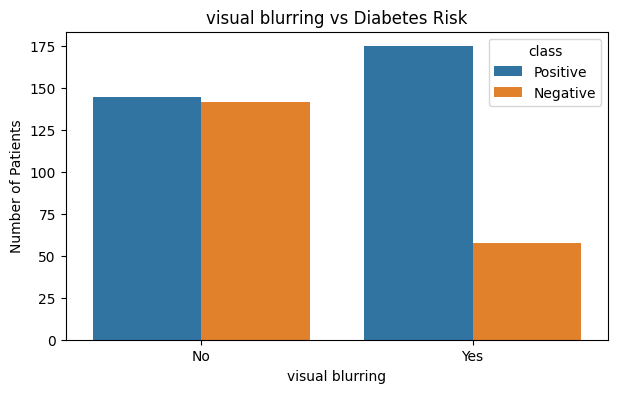

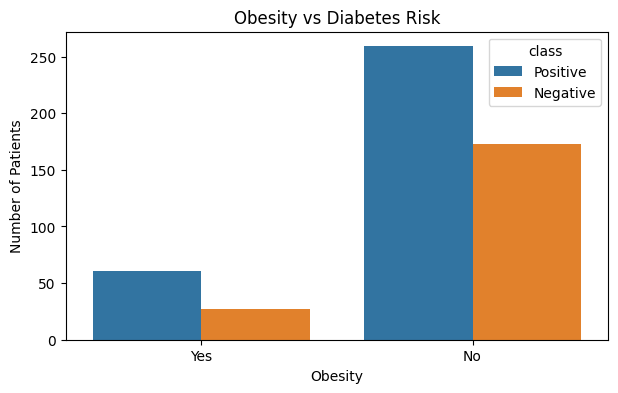

In [12]:
important_symptoms = [
    "Polyuria",
    "Polydipsia",
    "sudden weight loss",
    "weakness",
    "Polyphagia",
    "visual blurring",
    "Obesity"
]

for symptom in important_symptoms:

    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=symptom,
        hue="class"
    )

    plt.title(f"{symptom} vs Diabetes Risk")
    plt.xlabel(symptom)
    plt.ylabel("Number of Patients")

    plt.show()

In [13]:
encoding = {
    "Yes": 1,
    "No": 0,
    "Male": 1,
    "Female": 0,
    "Positive": 1,
    "Negative": 0
}

encoded_df = df.replace(encoding)

print("Categorical values encoded successfully.")

display(encoded_df.head())

Categorical values encoded successfully.


/tmp/ipykernel_2576/2437051128.py:10: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  encoded_df = df.replace(encoding)


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


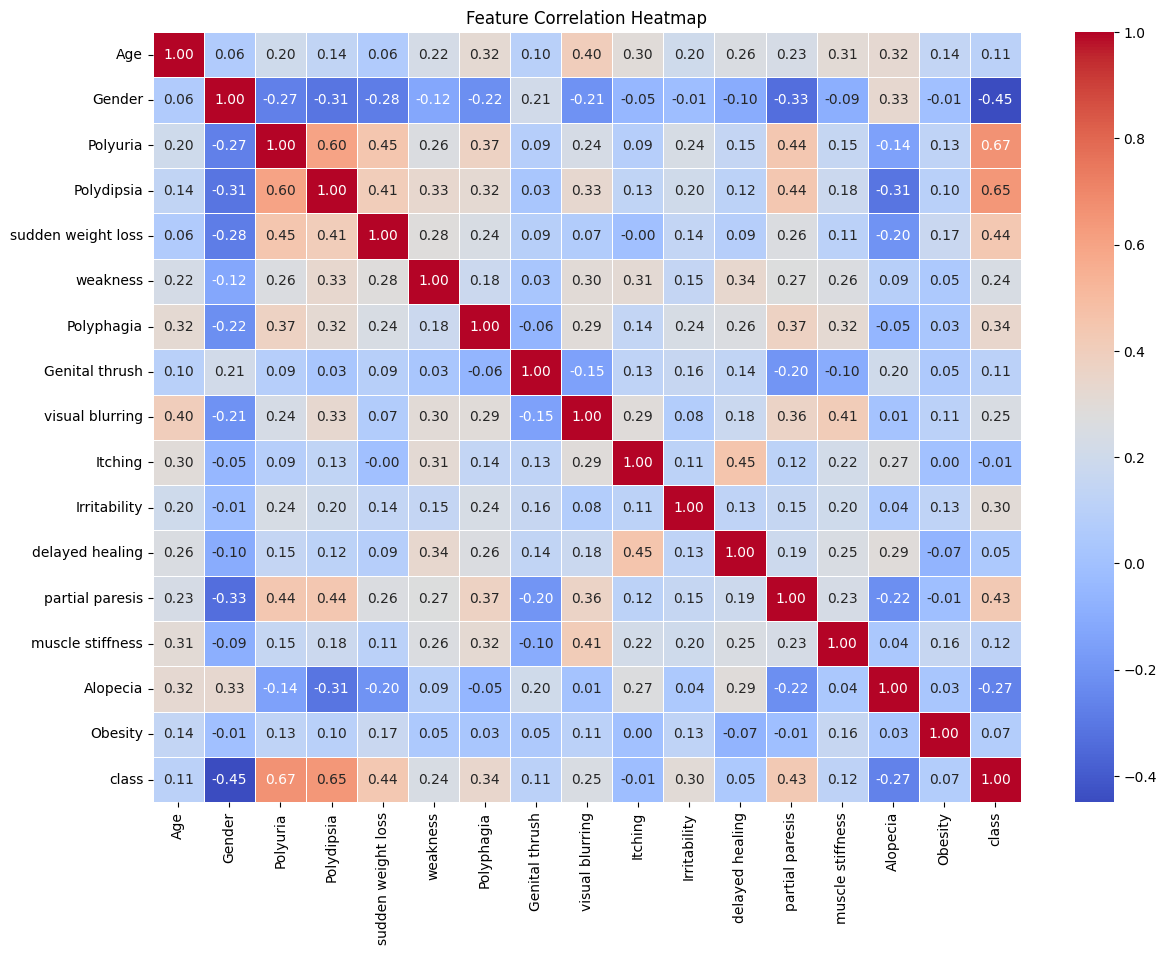

In [14]:
correlation = encoded_df.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [15]:
print("========== EDA SUMMARY ==========")

print("Original records:", df.shape[0])
print("Total features:", df.shape[1] - 1)
print("Target column: class")
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["class"].value_counts())

print("\nEDA completed successfully!")

========== EDA SUMMARY ==========
Original records: 520
Total features: 16
Target column: class
Missing values: 0
Duplicate records: 269

Target distribution:
class
Positive    320
Negative    200
Name: count, dtype: int64

EDA completed successfully!
